## TASK 1 - Blob detection
Group Number: 12

### 1. Data import and preparation

Read an input image from your local directory as grayscale and normalize the values between 0 and 1.

In [6]:
%load_ext autoreload
%autoreload 1
%aimport filters, utils
from skimage.feature import peak_local_max
import matplotlib.pyplot as plt
import numpy as np
import filters
import utils
import cv2

# Adjust size of image plot here
plt.rcParams['figure.figsize'] = [8, 5]
plt.rcParams['figure.dpi'] = 150

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
#student_code start
img = cv2.imread('data/butterfly.jpg', cv2.IMREAD_GRAYSCALE).astype(np.float64) / 255.0
print(img.shape, img.dtype, img.min(), img.max())
#student_code end

(356, 493) float64 0.0 1.0


### 2. Scale Space Creation

Generate the image pyramid using ***get_log_pyramid(..)*** in _filters.py_. Check your results with ***utils.show_plot(..)***

***Submission:*** Save the *third level* of the image scale space of the butterfly as **task1_filtered.png** using ***utils.show_plot(..)***.


(356, 493, 10) [ 2.          2.6         3.38        4.394       5.7122      7.42586
  9.653618   12.5497034  16.31461442 21.20899875]


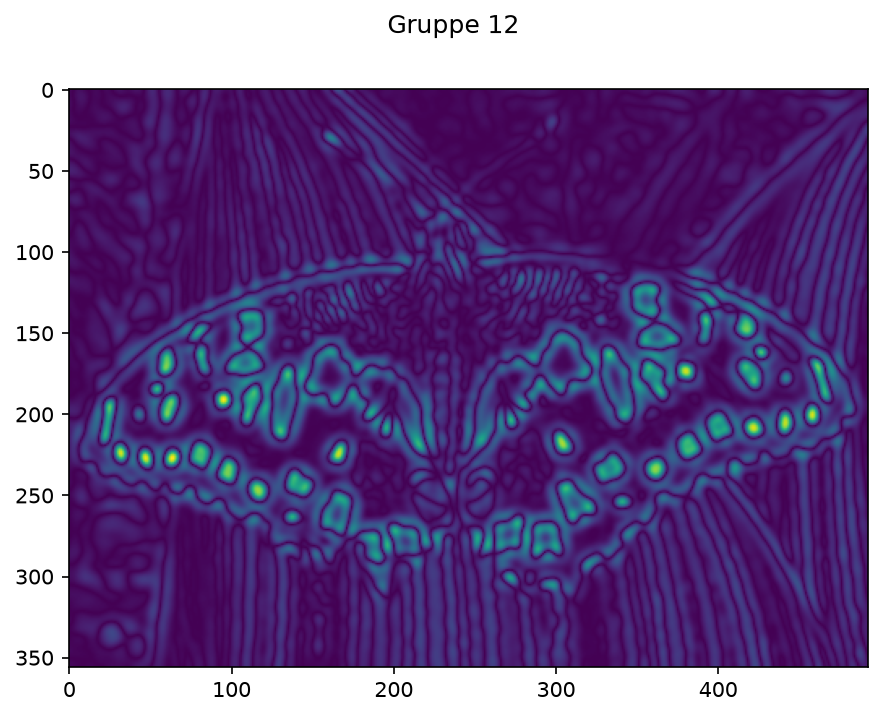

In [10]:
sigma = 2
k = 1.3
levels = 10

#student_code start
scale_space, all_sigmas = filters.get_log_pyramid(img, sigma, k, levels)
print(scale_space.shape, all_sigmas)
utils.show_plot(scale_space[:, :, 2], "Gruppe 12", "task1_filtered.png")

#student_code end

### 2. Blob detection

Perform the first step of the non-maximum suppression by setting the values in the scale space below a certain threshold to zero. Then, look for maxima in a defined local neighbourhood, in this case: the 26-connection. ***skimage.feature.peak_local_max(..)*** is useful to obtain local maxima. Complete method ***utils.show_blobs(..)*** and plot the blobs.


***Submission:*** Save the image including the blobs as **task1_blobs_full.png** (threshold around 0.3).

(196, 3)


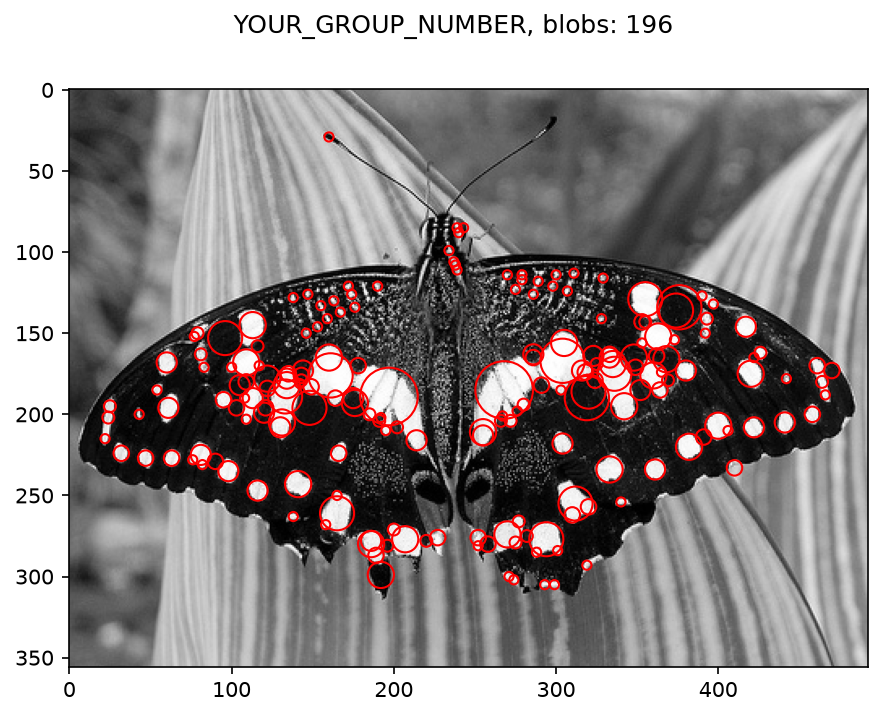

In [11]:
thres = 0.3

#student_code start
peaks = peak_local_max(scale_space, threshold_abs=thres,
                       footprint=np.ones((3, 3, 3)), exclude_border=0)
print(peaks.shape)
utils.show_blobs(img, peaks, all_sigmas, "YOUR_GROUP_NUMBER", "task1_blobs_full.png")

#student_code end


### 3. Evaluation 

Apply the process to a half-sized version of the input image. Plot your results as well with ***utils.show_blobs(..)***.

_***HINT:***_
_cv2.resize(..)_


***Submission:*** Save the result as **task1_blobs_half.png**.

In [ ]:
#student_code start


#student_code end

*** 
#### Taking a close look at the detected blobs on different image scales, is the method able to find blobs in a scale-invariant way? What could be reasons for observed errors or inaccurately detected blobs? 

#ANSWER HERE

#### 3.1 LoG Response

Pick a detected keypoint and plot the response of the LoG for all scales in both image versions. The outcome should be a 2D plot where the x-axis represents the scale of the filter and the y-axis the filter response at the selected keypoint position. 

_***HINT:***_
_plt.plot(..)_

In [ ]:
#student_code start

#student_code end

*** 
#### Describe and explain the difference between the two LoG response curves.

#ANSWER_HERE

#### 3.2 Own Image

Import an image of your choice and apply the process once again. 


***Submission:*** Save the image including blobs with ***utils.show_blobs(..)*** as: **task1_blobs_own.png**

In [ ]:
#student_code start

#student_code end